In [ ]:
import os, csv, random, tarfile, urllib.request
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn.functional as F
from torchvision import models
from torchvision.datasets import ImageFolder

%pip -q install grad-cam
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Device: cpu


In [ ]:
url = 'https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz'
archive = Path('/content/imagenette2-160.tgz')
root = Path('/content/imagenette2-160')
if not (root / 'val').exists():
    if not archive.exists():
        print('Downloading ImageNette...')
        urllib.request.urlretrieve(url, archive)
    print('Extracting ImageNette...')
    with tarfile.open(archive, 'r:gz') as tar:
        for member in tar.getmembers():
            target = (Path('/content') / member.name).resolve()
            if not str(target).startswith('/content/imagenette2-160/') and target != root:
                raise ValueError('Unexpected archive path: ' + member.name)
            if member.issym() or member.islnk():
                raise ValueError('Unexpected link in archive')
        tar.extractall('/content')
dataset = ImageFolder(root / 'val')
print('Validation images:', len(dataset))
print('Folder labels:', dataset.classes)
examples = []
for class_idx in range(len(dataset.classes)):
    matches = [path for path, label in dataset.samples if label == class_idx]
    examples.append(Path(random.choice(matches)))
print('Selected', len(examples), 'images')

Extracting ImageNette...


/tmp/ipykernel_1841/1106955107.py:16: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall('/content')


Validation images: 3925
Folder labels: ['n01440764', 'n02102040', 'n02979186', 'n03000684', 'n03028079', 'n03394916', 'n03417042', 'n03425413', 'n03445777', 'n03888257']
Selected 10 images


In [ ]:
resnet_weights = models.ResNet18_Weights.DEFAULT
vit_weights = models.ViT_B_16_Weights.DEFAULT
resnet = models.resnet18(weights=resnet_weights).to(device).eval()
vit = models.vit_b_16(weights=vit_weights).to(device).eval()
resnet_preprocess = resnet_weights.transforms()
vit_preprocess = vit_weights.transforms()
resnet_labels = resnet_weights.meta['categories']
vit_labels = vit_weights.meta['categories']
print('Models loaded successfully.')

Models loaded successfully.


In [ ]:
def resnet_gradcam(pil_image):
    tensor = resnet_preprocess(pil_image).unsqueeze(0).to(device)
    with torch.no_grad():
        scores = resnet(tensor)
        probs = torch.softmax(scores, dim=1)[0]
        idx = int(probs.argmax().item())
        confidence = float(probs[idx].item())

    with GradCAM(model=resnet, target_layers=[resnet.layer4[-1]]) as cam:
        heatmap = cam(input_tensor=tensor, targets=None)[0]

    rgb = np.asarray(pil_image.convert('RGB').resize((224, 224)), dtype=np.float32) / 255.0
    overlay = show_cam_on_image(rgb, heatmap, use_rgb=True)
    return resnet_labels[idx], confidence, overlay

In [ ]:
def vit_attention_rollout(pil_image):
    tensor = vit_preprocess(pil_image).unsqueeze(0).to(device)
    captured = []
    hooks = []

    def make_hook(attn_module):
        def capture(module, inputs):
            x = inputs[0].detach()
            d = x.shape[-1]
            num_heads = module.num_heads
            head_dim = d // num_heads
            qkv = F.linear(x, module.in_proj_weight, module.in_proj_bias)
            q, k, _ = qkv.chunk(3, dim=-1)
            q = q.reshape(1, -1, num_heads, head_dim).transpose(1, 2)
            k = k.reshape(1, -1, num_heads, head_dim).transpose(1, 2)
            attn = (q @ k.transpose(-2, -1)) * (head_dim ** -0.5)
            attn = attn.softmax(dim=-1).mean(dim=1)[0]  # [tokens, tokens]
            captured.append(attn.cpu())
        return capture

    for block in vit.encoder.layers:
        hooks.append(block.self_attention.register_forward_pre_hook(make_hook(block)))
    try:
        with torch.no_grad():
            scores = vit(tensor)
    finally:
        for hook in hooks:
            hook.remove()

    probs = scores.softmax(dim=1)[0]
    idx = int(probs.argmax().item())
    confidence = float(probs[idx].item())
    assert len(captured) == len(vit.encoder.layers), 'Not all attention layers were captured'

    tokens = captured[0].shape[0]
    rollout = torch.eye(tokens)
    for attention in captured:
        attention = attention + torch.eye(tokens)
        attention = attention / attention.sum(dim=-1, keepdim=True)
        rollout = attention @ rollout

    patch_scores = rollout[0, 1:]
    grid_side = int(np.sqrt(patch_scores.numel()))
    assert grid_side ** 2 == patch_scores.numel()
    heatmap = patch_scores.reshape(grid_side, grid_side).numpy()
    heatmap -= heatmap.min()
    heatmap /= heatmap.max() + 1e-8
    heatmap_img = Image.fromarray(np.uint8(heatmap * 255)).resize((224, 224), Image.Resampling.BILINEAR)
    heatmap = np.asarray(heatmap_img, dtype=np.float32) / 255.0
    rgb = np.asarray(pil_image.convert('RGB').resize((224, 224)), dtype=np.float32) / 255.0
    overlay = show_cam_on_image(rgb, heatmap, use_rgb=True)
    return vit_labels[idx], confidence, overlay

GRAD-CAM VS VISION TRANSFORMER - EXPERIMENT RESULTS

Total images tested: 10

PREDICTIONS AND CONFIDENCE SCORES:



,image_path,imagenette_folder_label,resnet_prediction,resnet_confidence,vit_prediction,vit_confidence,same_prediction
0,/content/imagenette2-160/val/n01440764/n014407...,n01440764,tench,0.7328,tench,0.8247,True
1,/content/imagenette2-160/val/n02102040/n021020...,n02102040,Cardigan,0.3007,English springer,0.6264,False
2,/content/imagenette2-160/val/n02979186/n029791...,n02979186,tape player,0.3729,CD player,0.3618,False
3,/content/imagenette2-160/val/n03000684/n030006...,n03000684,chain saw,0.2491,chain saw,0.8964,True
4,/content/imagenette2-160/val/n03028079/n030280...,n03028079,monastery,0.8655,monastery,0.8462,True
5,/content/imagenette2-160/val/n03394916/n033949...,n03394916,French horn,0.9975,French horn,0.8713,True
6,/content/imagenette2-160/val/n03417042/n034170...,n03417042,garbage truck,0.9469,garbage truck,0.9000,True
7,/content/imagenette2-160/val/n03425413/n034254...,n03425413,thresher,0.8750,gas pump,0.4818,False
8,/content/imagenette2-160/val/n03445777/n034457...,n03445777,golf ball,0.9995,golf ball,0.8776,True
9,/content/imagenette2-160/val/n03888257/n038882...,n03888257,parachute,0.8985,parachute,0.9114,True



GRAD-CAM AND ViT VISUALIZATION COMPARISONS


### Comparison 1: comparison_01

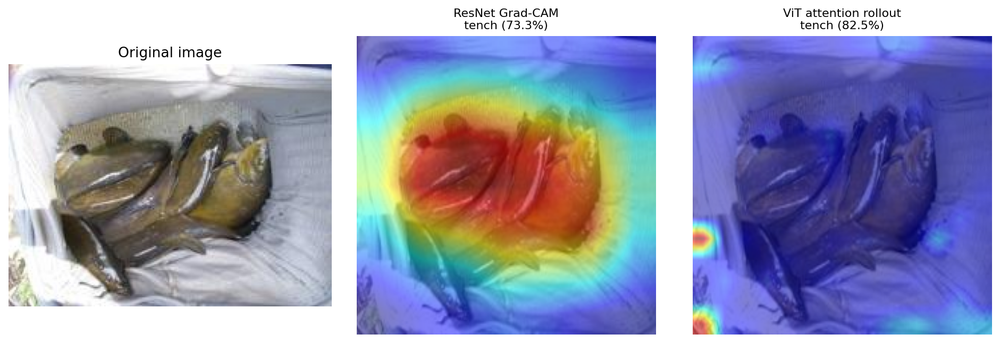

### Comparison 2: comparison_02

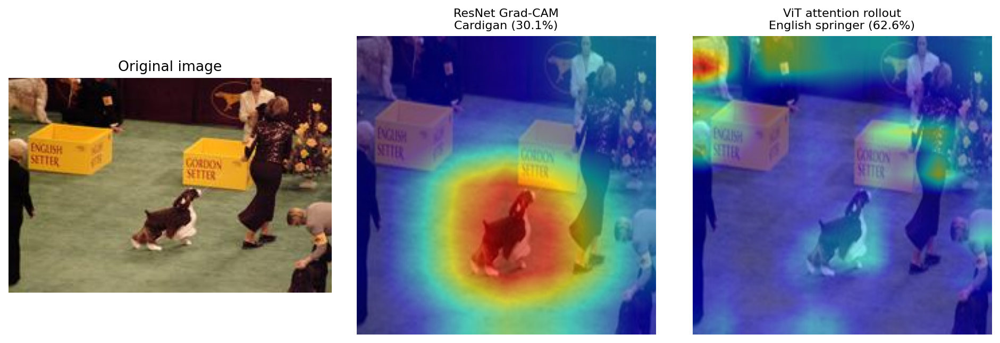

### Comparison 3: comparison_03

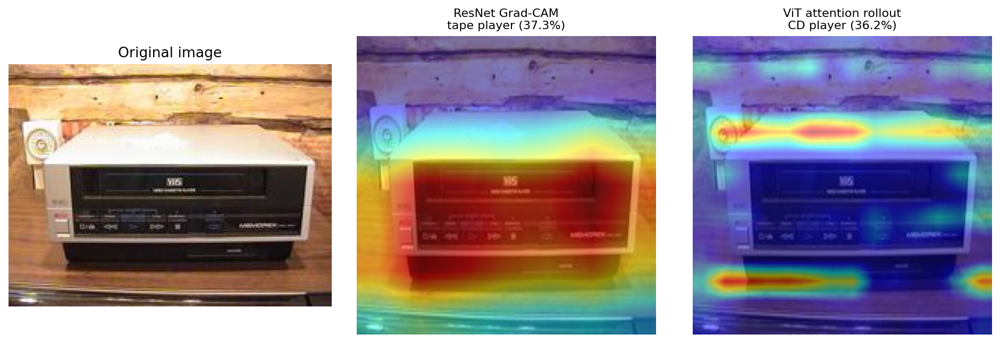

### Comparison 4: comparison_04

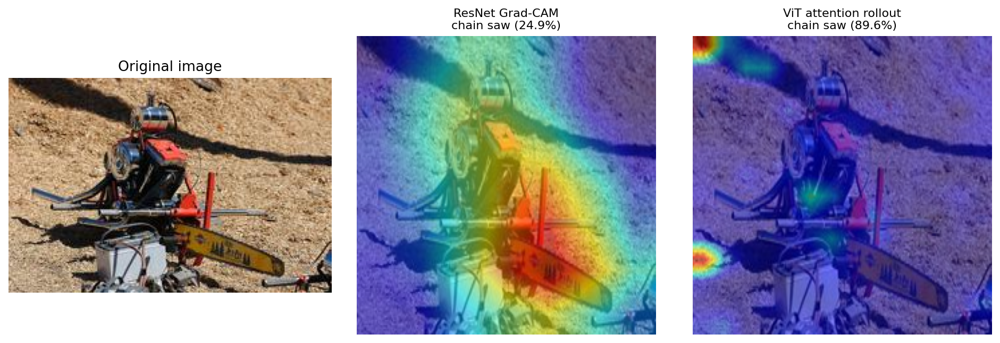

### Comparison 5: comparison_05

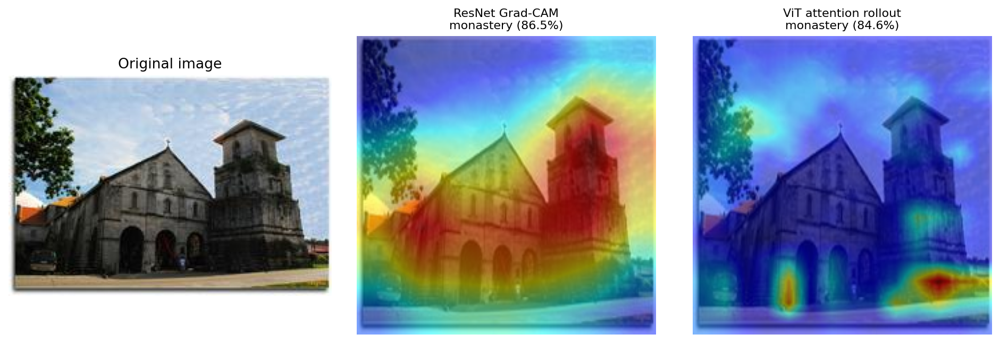

### Comparison 6: comparison_06

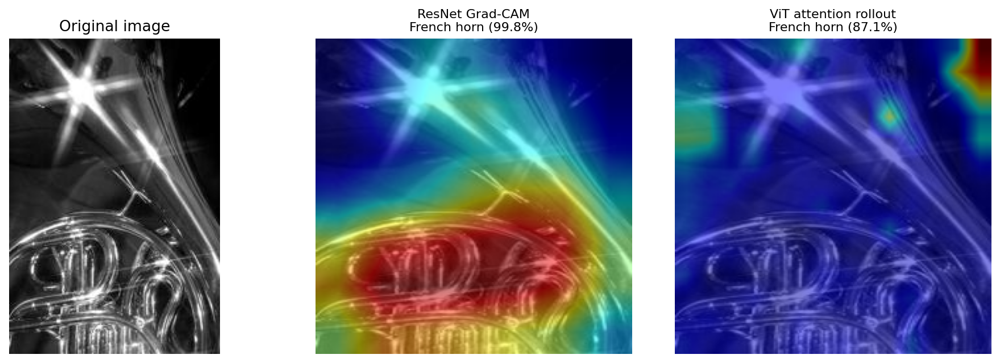

### Comparison 7: comparison_07

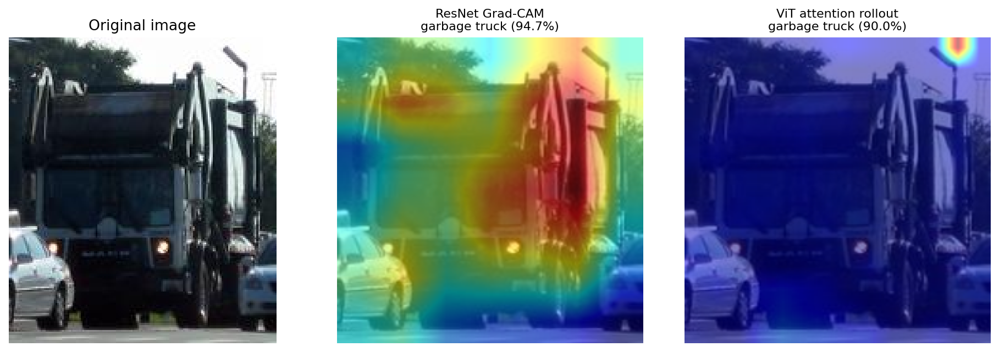

### Comparison 8: comparison_08

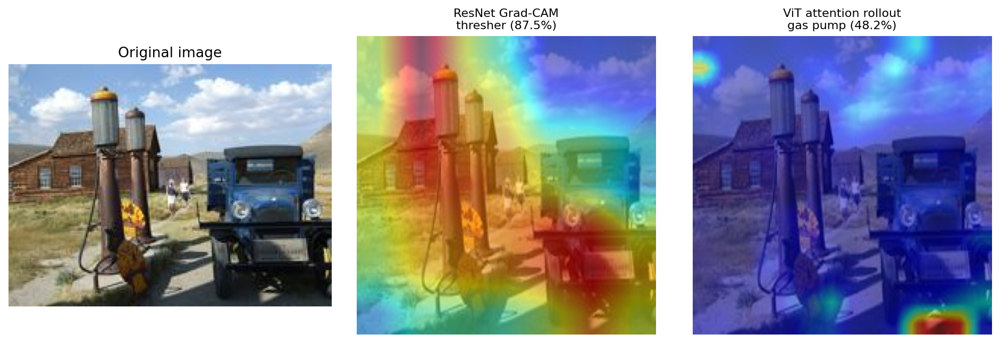

### Comparison 9: comparison_09

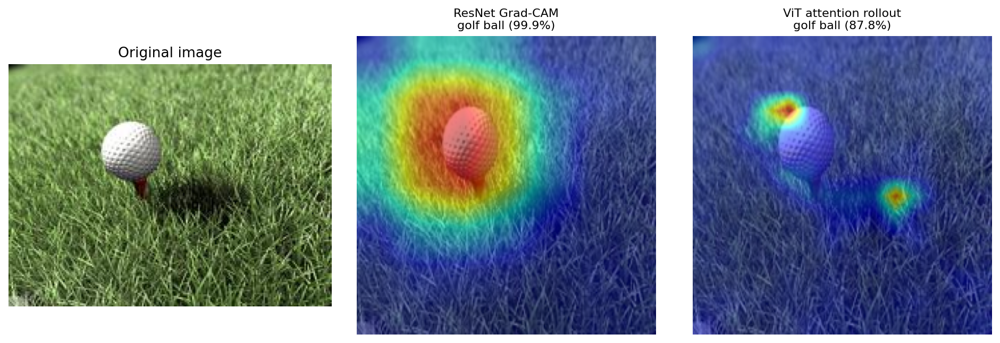

### Comparison 10: comparison_10

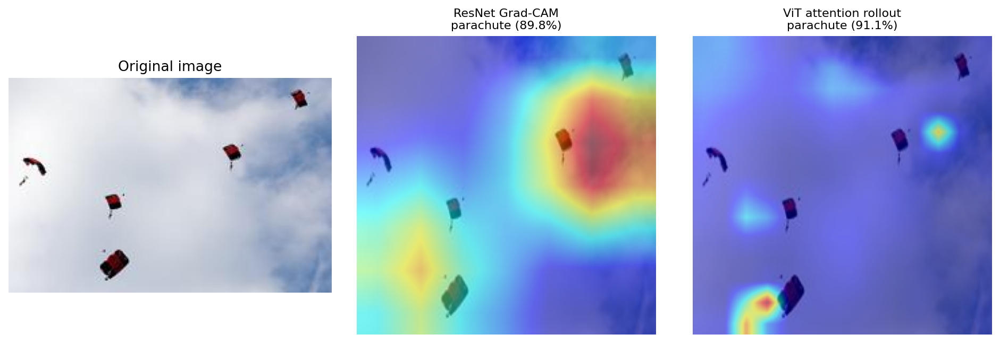

In [ ]:

from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Markdown

search_folders = [
    Path("/content/results"),
    Path("/content/outputs"),
    Path("/content"),
    Path(".")
]

csv_files = []
for folder in search_folders:
    if folder.exists():
        csv_files.extend(folder.rglob("predictions.csv"))

csv_files = list(dict.fromkeys(p.resolve() for p in csv_files))

if not csv_files:
    print("Could not find predictions.csv.")
    print("Check where your notebook saves the results.")
else:
    csv_path = csv_files[0]
    results_dir = csv_path.parent

    print("=" * 65)
    print("GRAD-CAM VS VISION TRANSFORMER - EXPERIMENT RESULTS")
    print("=" * 65)

    df = pd.read_csv(csv_path)

    print(f"\nTotal images tested: {len(df)}")
    print("\nPREDICTIONS AND CONFIDENCE SCORES:\n")

    display(df)

    print("\n" + "=" * 65)
    print("GRAD-CAM AND ViT VISUALIZATION COMPARISONS")
    print("=" * 65)

    image_files = sorted(
        p for p in results_dir.rglob("*")
        if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
        and (
            "comparison" in p.name.lower()
            or "compare" in p.name.lower()
        )
    )

    if not image_files:
        print("\nNo comparison images found in:", results_dir)
        print("Check the image filenames and output folder.")
    else:
        for i, img_path in enumerate(image_files, 1):
            display(Markdown(f"### Comparison {i}: {img_path.stem}"))
            display(Image(filename=str(img_path), width=900))